In [1]:
%load_ext autoreload
%autoreload 2
import os
if not "monosynaptic.py" in os.listdir():
    os.chdir("..")

from monosynaptic import Monosynaptic
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

[2026-07-24 13:20:17,168][INFO]: DataJoint 0.14.9 connected to sambray@lmf-db.cin.ucsf.edu:3306


# Define data of interest

In [2]:
nwb_file_name = 'mango20211129_.nwb'
interval_list_name = '15_s8'
sorted_spikes_group = 'mPFC_targeted_raw data valid times no premaze no home_v2'

key = {
    "nwb_file_name": nwb_file_name,
    "sorted_spikes_group_name": sorted_spikes_group,
    "interval_list_name": interval_list_name
}

Monosynaptic & key

nwb_file_name name of the NWB file,unit_filter_params_name,sorted_spikes_group_name,interval_list_name descriptive name of this interval list,cross_corr_params_name,shuffle_params_name,monosynaptic_params_name Name of the monosynaptic parameters,analysis_file_name name of the file,monosynaptic_object_id
mango20211129_.nwb,include_accept,mPFC_targeted_raw data valid times no premaze no home_v2,15_s8,monosynaptic,monosynaptic,default,mango20211129_4APH89AXDT.nwb,18630535-f38f-458e-8f3b-5b414ac94a01


## Get monosynaptic pairs

Note: this gives the monosynaptic interaction of `unit_id_2` onto `unit_id_1`

In [3]:
mono_df = (Monosynaptic & key).fetch1_dataframe()
mono_df[:10]

/home/sambray/.local/lib/python3.10/site-packages/hdmf/build/objectmapper.py:1399: UserWarning: Device.model was detected as a string, but NWB 2.9 specifies Device.model as a link to a DeviceModel. Remapping "unknown" to a new DeviceModel.
  override = self.__get_override_carg(argname, builder, manager)


,unit_id_1,unit_id_2,interaction
id,,,
0,22768911-01fb-2bf2-aeb0-b3f1ba5bcd56_19,22768911-01fb-2bf2-aeb0-b3f1ba5bcd56_18,excitatory
1,22768911-01fb-2bf2-aeb0-b3f1ba5bcd56_28,22768911-01fb-2bf2-aeb0-b3f1ba5bcd56_18,excitatory
2,6472ba8d-c3f7-55a7-b870-926263499e37_7,6472ba8d-c3f7-55a7-b870-926263499e37_8,excitatory
3,6472ba8d-c3f7-55a7-b870-926263499e37_26,6472ba8d-c3f7-55a7-b870-926263499e37_13,excitatory
4,6472ba8d-c3f7-55a7-b870-926263499e37_26,6472ba8d-c3f7-55a7-b870-926263499e37_15,excitatory
5,6472ba8d-c3f7-55a7-b870-926263499e37_26,6472ba8d-c3f7-55a7-b870-926263499e37_16,excitatory
6,6472ba8d-c3f7-55a7-b870-926263499e37_26,6472ba8d-c3f7-55a7-b870-926263499e37_17,excitatory
7,6472ba8d-c3f7-55a7-b870-926263499e37_26,6472ba8d-c3f7-55a7-b870-926263499e37_30,excitatory
8,6472ba8d-c3f7-55a7-b870-926263499e37_54,6472ba8d-c3f7-55a7-b870-926263499e37_52,excitatory


## Get neurons identified as excitatory or inhibitory by monosynaptic interaction

In [4]:
(Monosynaptic & key).get_neuron_types()

{'inhibitory': array(['22768911-01fb-2bf2-aeb0-b3f1ba5bcd56_28',
        '22768911-01fb-2bf2-aeb0-b3f1ba5bcd56_19',
        '6472ba8d-c3f7-55a7-b870-926263499e37_1',
        '6472ba8d-c3f7-55a7-b870-926263499e37_7',
        '6472ba8d-c3f7-55a7-b870-926263499e37_26',
        '6472ba8d-c3f7-55a7-b870-926263499e37_23',
        '6472ba8d-c3f7-55a7-b870-926263499e37_20',
        '6472ba8d-c3f7-55a7-b870-926263499e37_54',
        '7b98ed21-4c10-f8e1-7171-6ee184b8f59e_1',
        '7b98ed21-4c10-f8e1-7171-6ee184b8f59e_0'], dtype=object),
 'excitatory': array(['22768911-01fb-2bf2-aeb0-b3f1ba5bcd56_18',
        '6472ba8d-c3f7-55a7-b870-926263499e37_8',
        '6472ba8d-c3f7-55a7-b870-926263499e37_13',
        '6472ba8d-c3f7-55a7-b870-926263499e37_15',
        '6472ba8d-c3f7-55a7-b870-926263499e37_16',
        '6472ba8d-c3f7-55a7-b870-926263499e37_17',
        '6472ba8d-c3f7-55a7-b870-926263499e37_30',
        '6472ba8d-c3f7-55a7-b870-926263499e37_52',
        'a28f9375-000a-1f63-954a-43cc6c9267

# Validate interactions mostly identified for neurons in the same sort group

excitatory: 13
Number of monosynaptic pairs on the same shank: 13 / 13
inhibitory: 12
Number of monosynaptic pairs on the same shank: 12 / 12


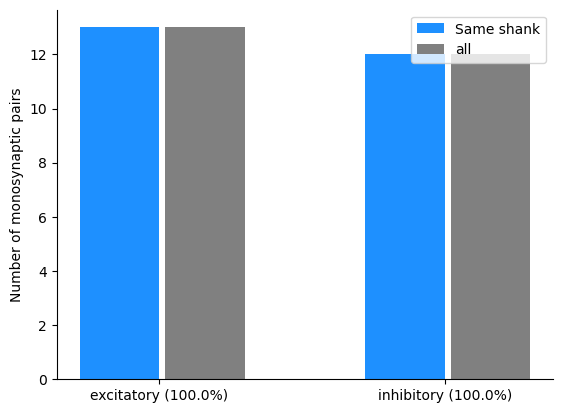

In [5]:
fig = (Monosynaptic & key).validate_shank_source()

# Load Correlogram data

In [8]:
corr_df = (Monosynaptic & key).fetch_correlogram_df()
corr_df[:3]

,unit_id_1,unit_id_2,correlogram,counts_1,counts_2,bins,lower_bound,upper_bound
0,22768911-01fb-2bf2-aeb0-b3f1ba5bcd56_0,22768911-01fb-2bf2-aeb0-b3f1ba5bcd56_0,"[7.490636704119844, 5.82605076987099, 6.658343...",2403,2403,"[-0.01975, -0.01925, -0.01875, -0.01825, -0.01...","[0.0, 0.832292967124427, 0.832292967124427, 0....","[17.478152309612966, 18.310445276737394, 15.81..."
1,22768911-01fb-2bf2-aeb0-b3f1ba5bcd56_0,22768911-01fb-2bf2-aeb0-b3f1ba5bcd56_1,"[23.30420307948396, 18.310445276737394, 25.801...",2403,48391,"[-0.01975, -0.01925, -0.01875, -0.01825, -0.01...","[14.14898044111526, 13.316687473990832, 14.148...","[42.446941323345776, 43.27923429047021, 43.279..."
2,22768911-01fb-2bf2-aeb0-b3f1ba5bcd56_0,22768911-01fb-2bf2-aeb0-b3f1ba5bcd56_2,"[0.832292967124427, 1.664585934248854, 2.49687...",2403,3127,"[-0.01975, -0.01925, -0.01875, -0.01825, -0.01...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[5.82605076987099, 5.82605076987099, 5.8260507..."


# Look at cross Correlograms of identified Interactions

Text(0.5, 0, 'Lag Time (ms)')

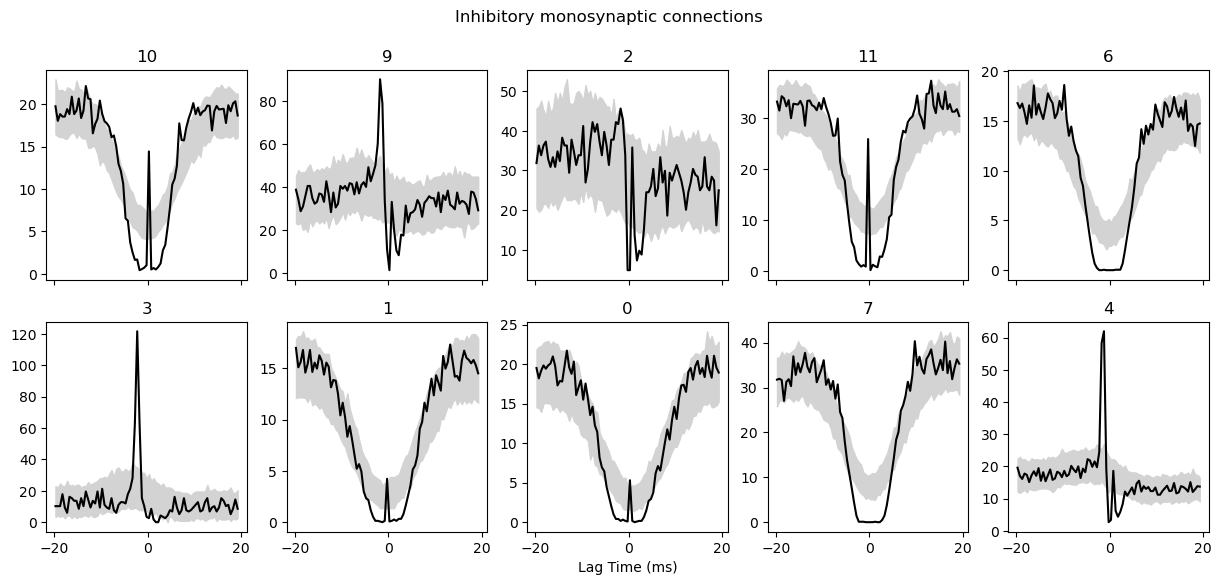

In [ ]:
inhib_df = mono_df[mono_df["interaction"]=="inhibitory"]
inhibitory_samp = np.random.choice(len(inhib_df), 10, replace=False)
fig, ax = plt.subplots(2,5,figsize=(15,6),sharex=True)
for i, ind in enumerate(inhibitory_samp):
    unit_1 = inhib_df["unit_id_1"].iloc[ind]
    unit_2 = inhib_df["unit_id_2"].iloc[ind]

    test_df = corr_df[(corr_df["unit_id_1"]==unit_1) & (corr_df["unit_id_2"]==unit_2)]
    bins = test_df["bins"].values[0] *1000
    corr = test_df["correlogram"].values[0]
    lb = test_df["lower_bound"].values[0]
    ub = test_df["upper_bound"].values[0]

    ax[i//5,i%5].fill_between(bins, lb, ub, color="lightgrey", label="shuffle distribution",zorder=-1)
    ax[i//5,i%5].plot(bins, corr, color="black", label="Cross-correlogram")
    ax[i//5,i%5].set_title(ind)

    fig.suptitle("Inhibitory monosynaptic connections")

ax[1,2].set_xlabel("Lag Time (ms)")

Text(0.5, 0, 'Lag Time (ms)')

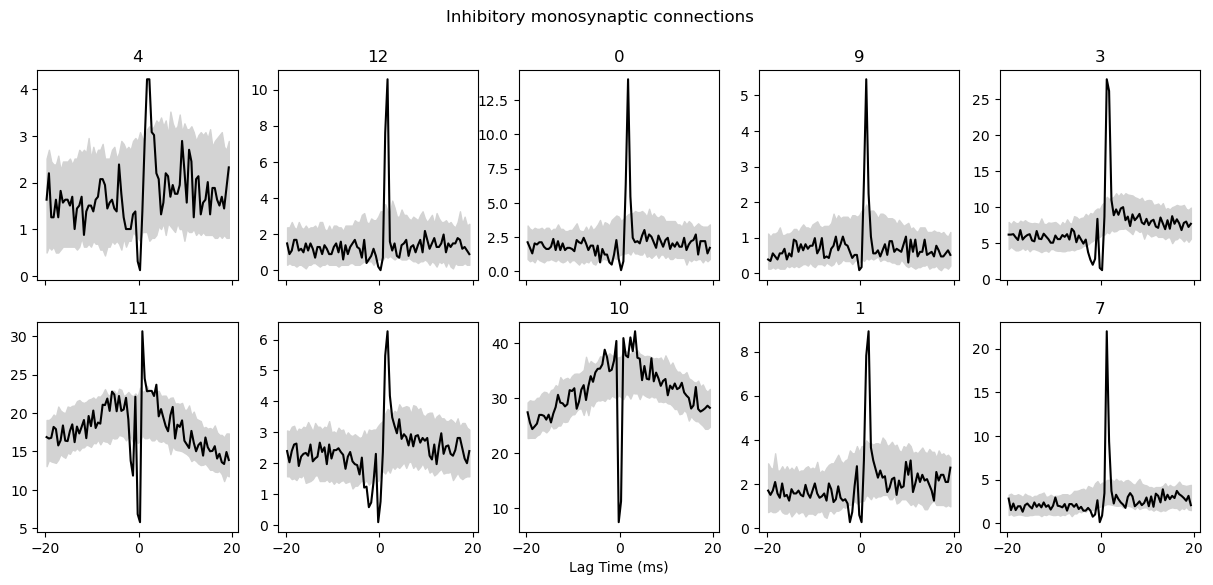

In [ ]:
excitatory_df = mono_df[mono_df["interaction"]=="excitatory"]
excitatory_samp = np.random.choice(len(excitatory_df), 10, replace=False)
fig, ax = plt.subplots(2,5,figsize=(15,6),sharex=True)
for i, ind in enumerate(excitatory_samp):
    unit_1 = excitatory_df["unit_id_1"].iloc[ind]
    unit_2 = excitatory_df["unit_id_2"].iloc[ind]

    test_df = corr_df[(corr_df["unit_id_1"]==unit_1) & (corr_df["unit_id_2"]==unit_2)]
    bins = test_df["bins"].values[0] *1000
    corr = test_df["correlogram"].values[0]
    lb = test_df["lower_bound"].values[0]
    ub = test_df["upper_bound"].values[0]

    ax[i//5,i%5].fill_between(bins, lb, ub, color="lightgrey", label="shuffle distribution",zorder=-1)
    ax[i//5,i%5].plot(bins, corr, color="black", label="Cross-correlogram")
    ax[i//5,i%5].set_title(ind)

    fig.suptitle("Inhibitory monosynaptic connections")

ax[1,2].set_xlabel("Lag Time (ms)")